# TinyML 2026 · Del entrenamiento en Google Colab a Arduino Nano 33 BLE Sense

**Práctica guiada | Introducción al TinyML | Versión 1.0 — 26 de octubre de 2026**

**Objetivo:** entrenar una red neuronal que aproxime $y=\sin(x)$, evaluar su desempeño, cuantizarla a **INT8**, convertirla a un modelo **TensorFlow Lite (`.tflite`)**, incorporarla como un arreglo C/C++ en `model.h` y generar un **sketch para Arduino IDE 2.x** que ejecute inferencia real con TensorFlow Lite Micro.

> **Placas:** Arduino Nano 33 BLE Sense (original) y **Nano 33 BLE Sense Rev2**, así como otras placas ARM Mbed compatibles. Para una primera práctica no se usan micrófono ni IMU; por lo tanto, el cambio de sensores entre Rev1 y Rev2 no afecta a este ejemplo. La biblioteca empleada es **Chirale_TensorFlowLite 2.0.0 (2024)**, una adaptación Arduino de TFLM. Es de terceros y conviene validar la compilación con la versión de Arduino Mbed OS Nano Boards que se instale.

**Entregables automáticos de este notebook:**
- `modelo_seno_int8.tflite`: modelo cuantizado.
- `model.h`: bytes del modelo, alineados para el microcontrolador.
- `TinyML_Seno_Nano33BLE.ino`: sketch de inferencia y salida al Serial Plotter.
- `README_Arduino.txt`: instrucciones para Arduino IDE.
- `metricas.json`: parámetros de cuantización y resultados.
- `TinyML_Seno_Arduino_Nano33BLE.zip`: proyecto Arduino listo para extraer y abrir.

**No necesitas hardware durante el entrenamiento.** La carga y ejecución en Arduino se realizan después, desde tu computadora.

**Referencias:** [TFLM principal](https://github.com/tensorflow/tflite-micro) · [Chirale Arduino](https://github.com/spaziochirale/Chirale_TensorFlowLite) · [Arduino Mbed OS Nano Boards](https://docs.arduino.cc/software/ide-v1/tutorials/getting-started/cores/arduino-mbed_nano/) · [Ejemplo histórico de Hello World](https://github.com/tensorflow/tflite-micro-arduino-examples/tree/main/examples/hello_world).

## 0. Preparar el entorno de Colab

Abre este `.ipynb` en Google Colab y elige **Entorno de ejecución → Ejecutar todo**. Colab normalmente incluye TensorFlow, NumPy y Matplotlib. Si `import tensorflow` falla, ejecuta primero `!pip -q install tensorflow` y reinicia el entorno.

Para reproducibilidad fijamos semillas. La versión de TensorFlow del entorno se imprime para registrar qué herramienta generó el FlatBuffer; **TFLM en Arduino y TensorFlow de Colab no son exactamente la misma biblioteca**.

In [19]:
import sys, json, math, zipfile, textwrap
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 2026
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

OUTPUT = Path('/content/tinyml_seno') if Path('/content').is_dir() else Path('tinyml_seno')
OUTPUT.mkdir(parents=True, exist_ok=True)

print('Python:', sys.version.split()[0])
print('TensorFlow:', tf.__version__)
print('NumPy:', np.__version__)
print('Archivos en:', OUTPUT.resolve())

Python: 3.13.18
TensorFlow: 2.21.0
NumPy: 2.1.3
Archivos en: /content/tinyml_seno


## 1. Preparación de datos

Entrenaremos con pares $(x,\sin(x))$, usando $x\in[0,2\pi]$ y una pequeña perturbación en la salida de entrenamiento. **Evaluaremos contra el seno exacto** en una rejilla independiente; así no confundiremos el ruido artificial con error del modelo.

La entrada del modelo tiene forma `(N, 1)` y su salida también. Estas formas son relevantes al programar los tensores de TFLM.

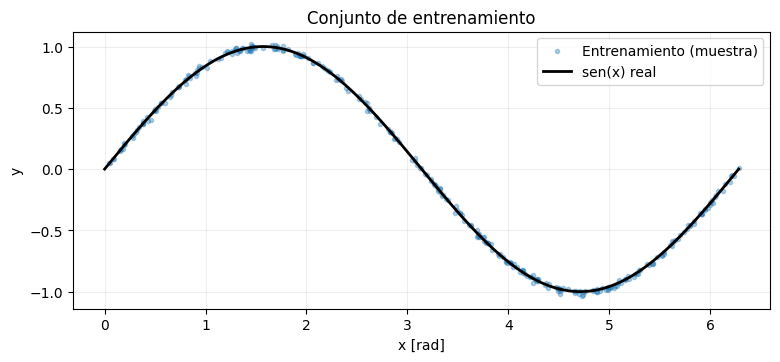

Formas: (1600, 1) (1600, 1) (320, 1) (256, 1)


In [20]:
rng = np.random.default_rng(SEED)
X_train = rng.uniform(0.0, 2*np.pi, size=(1600, 1)).astype(np.float32)
y_train = (np.sin(X_train) + rng.normal(0, 0.015, size=(1600, 1))).astype(np.float32)
X_val = rng.uniform(0.0, 2*np.pi, size=(320, 1)).astype(np.float32)
y_val = np.sin(X_val).astype(np.float32)
X_test = np.linspace(0, 2*np.pi, 256, dtype=np.float32).reshape(-1, 1)
y_test = np.sin(X_test).astype(np.float32)

plt.figure(figsize=(9, 3.6))
plt.scatter(X_train[::5, 0], y_train[::5, 0], s=9, alpha=0.35, label='Entrenamiento (muestra)')
plt.plot(X_test[:, 0], y_test[:, 0], color='black', linewidth=2, label='sen(x) real')
plt.xlabel('x [rad]'); plt.ylabel('y'); plt.title('Conjunto de entrenamiento')
plt.legend(); plt.grid(alpha=.2); plt.show()
print('Formas:', X_train.shape, y_train.shape, X_val.shape, X_test.shape)

## 2. Definir y entrenar el modelo

Una red pequeña **1 → 16 → 16 → 1**, con activaciones `tanh`, basta para ilustrar la aproximación de una función continua. La red se entrena **en la nube**; Arduino solo ejecutará inferencia.

`EarlyStopping` detiene el entrenamiento si deja de mejorar el error de validación. El número real de épocas depende de la ejecución.

Model: "seno_tinyml"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 965 (3.77 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 644 (2.52 KB)

Épocas ejecutadas: 118


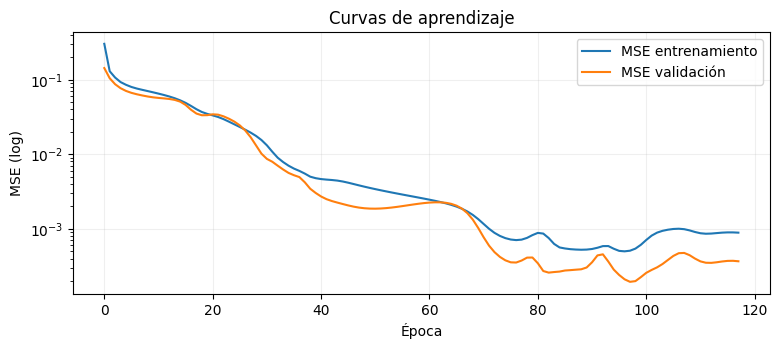

In [21]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,), dtype=tf.float32),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(1),
], name='seno_tinyml')
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss='mse',
    metrics=['mae'],
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200, batch_size=64, verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True
    )],
)
model.summary()
print('Épocas ejecutadas:', len(history.history['loss']))
plt.figure(figsize=(9, 3.4))
plt.plot(history.history['loss'], label='MSE entrenamiento')
plt.plot(history.history['val_loss'], label='MSE validación')
plt.yscale('log'); plt.xlabel('Época'); plt.ylabel('MSE (log)')
plt.title('Curvas de aprendizaje'); plt.legend(); plt.grid(alpha=.2); plt.show()

## 3. Evaluar el modelo de TensorFlow (float32)

Calculamos RMSE y MAE sobre una rejilla de prueba separada. Estos resultados son la referencia para medir la pérdida ocasionada por la cuantización.

Modelo float32: {
  "RMSE": 0.013900576159358025,
  "MAE": 0.011784065514802933,
  "Error_max": 0.03746641054749489
}


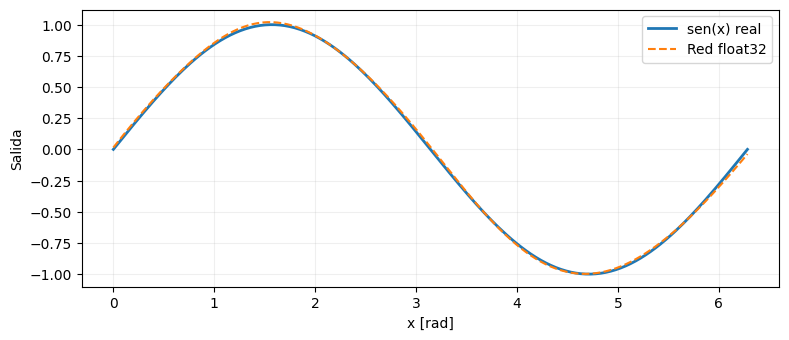

In [22]:
pred_fp32 = model.predict(X_test, verbose=0).reshape(-1)
y_true = y_test.reshape(-1)

def error_metrics(reference, prediction):
    return {
        'RMSE': float(np.sqrt(np.mean((reference - prediction)**2))),
        'MAE': float(np.mean(np.abs(reference - prediction))),
        'Error_max': float(np.max(np.abs(reference - prediction))),
    }

metric_fp32 = error_metrics(y_true, pred_fp32)
print('Modelo float32:', json.dumps(metric_fp32, indent=2))
plt.figure(figsize=(9, 3.6))
plt.plot(X_test[:, 0], y_true, label='sen(x) real', linewidth=2)
plt.plot(X_test[:, 0], pred_fp32, '--', label='Red float32')
plt.xlabel('x [rad]'); plt.ylabel('Salida'); plt.legend(); plt.grid(alpha=.2); plt.show()

## 4. Cuantización ENTERA completa (INT8)

`Optimize.DEFAULT` junto con un **representative dataset** permite calibrar activaciones. Al establecer `TFLITE_BUILTINS_INT8` y forzar entrada y salida `tf.int8`, evitamos que Arduino tenga que calcular entradas o salidas en coma flotante dentro del grafo.

**Importante:** la cuantización no se reduce a convertir bytes; en Arduino hay que aplicar las escalas y los ceros (`scale` y `zero_point`) a los datos de entrada y salida.

In [23]:
def representative_data():
    for x in np.linspace(0, 2*np.pi, 256, dtype=np.float32):
        yield [np.array([[x]], dtype=np.float32)]

def make_converter(strategy):
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    if strategy == 'M1':      # sin cuantizar, FP32
        pass
    elif strategy == 'M2':    # rango dinamico
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
    elif strategy == 'M3':    # float16
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
    elif strategy == 'M4':    # entera, entrada y salida float32
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.representative_dataset = representative_data
        converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    elif strategy == 'M5':    # entera completa, entrada y salida int8 (tu celda original)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.representative_dataset = representative_data
        converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        converter.inference_input_type = tf.int8
        converter.inference_output_type = tf.int8
    return converter

tflite_models = {}
for key in ['M1', 'M2', 'M3', 'M4', 'M5']:
    tflite_model = make_converter(key).convert()
    tflite_models[key] = tflite_model
    model_file = OUTPUT / f'modelo_seno_{key}.tflite'
    model_file.write_bytes(tflite_model)
    print(f'{key}: {len(tflite_model)} bytes -> {model_file}')

    # Inspeccion de operadores y tensores
    try:
        tf.lite.experimental.Analyzer.analyze(model_content=tflite_model)
    except Exception as exc:
        print('El analizador no esta disponible:', type(exc).__name__, exc)

Saved artifact at '/tmp/tmpjv3zc2y1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='keras_tensor_12')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  132388769985552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132388769986512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132388769986320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132388769986896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132388769986704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132388769987280: TensorSpec(shape=(), dtype=tf.resource, name=None)
M1: 3436 bytes -> /content/tinyml_seno/modelo_seno_M1.tflite
=== TFLite ModelAnalyzer ===

Your TFLite model has '1' subgraph(s). In the subgraph description below,
T# represents the Tensor numbers. For example, in Subgraph#0, the FULLY_CONNECTED op takes
tensor #0 and tensor #5 and tensor #6 as input 

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


M4: 4080 bytes -> /content/tinyml_seno/modelo_seno_M4.tflite
=== TFLite ModelAnalyzer ===

Your TFLite model has '1' subgraph(s). In the subgraph description below,
T# represents the Tensor numbers. For example, in Subgraph#0, the QUANTIZE op takes
tensor #0 as input and produces tensor #7 as output.

Subgraph#0 main(T#0) -> [T#13]
  Op#0 QUANTIZE(T#0) -> [T#7]
  Op#1 FULLY_CONNECTED(T#7, T#6, T#5[-9, 13832, 7993, -10802, -6608, ...]) -> [T#8]
  Op#2 TANH(T#8) -> [T#9]
  Op#3 FULLY_CONNECTED(T#9, T#4, T#3[-3209, 231, -2286, -2185, -1259, ...]) -> [T#10]
  Op#4 TANH(T#10) -> [T#11]
  Op#5 FULLY_CONNECTED(T#11, T#2, T#1[481]) -> [T#12]
  Op#6 DEQUANTIZE(T#12) -> [T#13]

Tensors of Subgraph#0
  T#0(serving_default_keras_tensor_12:0) shape_signature:[-1, 1], type:FLOAT32
  T#1(seno_tinyml_1/dense_11_1/Add) shape:[1], type:INT32 RO 4 bytes, buffer: 2, data:[481]
  T#2(seno_tinyml_1/dense_11_1/MatMul) shape:[1, 16], type:INT8 RO 16 bytes, buffer: 3, data:[., ., ., ., ., ...]
  T#3(seno_tinym

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Información de cuantización por modelo

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



== M1 | 3436 bytes | operadores: ['FULLY_CONNECTED', 'TANH', 'FULLY_CONNECTED', 'TANH', 'FULLY_CONNECTED'] ==
idx  rol         dtype    forma     scale (n)  zero_pt  rango representable
---------------------------------------------------------------------------
0    entrada     float32  [1, 1]    -          -        -                  
1    constante   float32  [1]       -          -        -                  
2    constante   float32  [16]      -          -        -                  
3    constante   float32  [1, 16]   -          -        -                  
4    constante   float32  [16, 16]  -          -        -                  
5    constante   float32  [16, 1]   -          -        -                  
6    constante   float32  [16]      -          -        -                  
7    activacion  float32  [1, 16]   -          -        -                  
8    activacion  float32  [1, 16]   -          -        -                  
9    activacion  float32  [1, 16]   -          -     

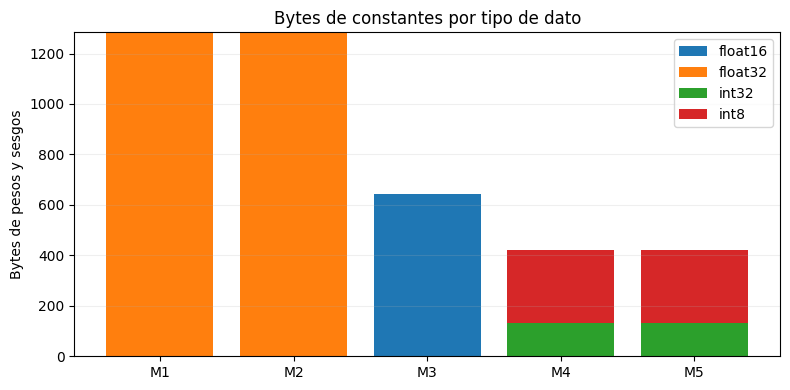

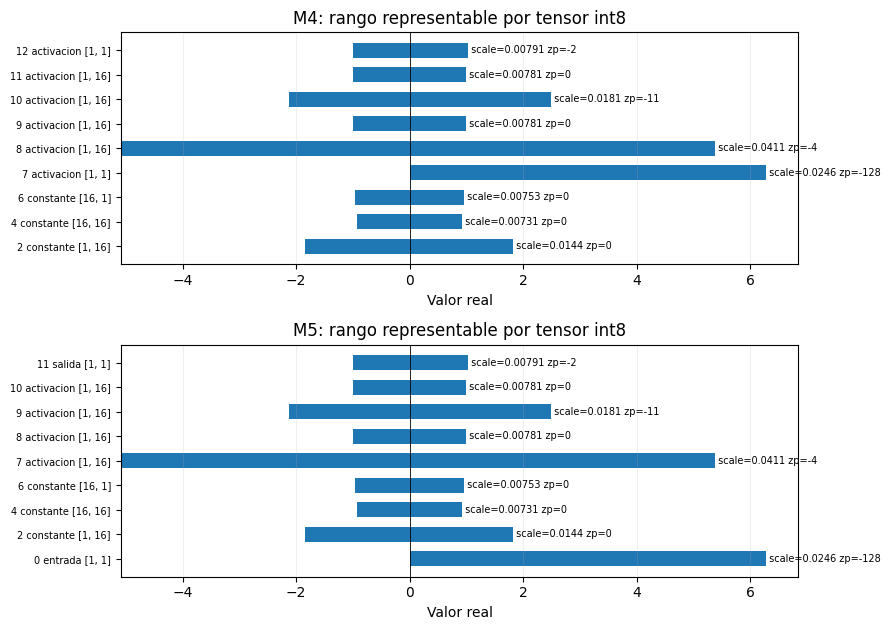

In [24]:
import csv

def collect_tensors(blob):
    it = tf.lite.Interpreter(model_content=blob)
    it.allocate_tensors()
    ops = it._get_ops_details()  # API privada
    produced = {int(o) for op in ops for o in op['outputs']}
    used = {int(i) for op in ops for i in op['inputs'] if int(i) >= 0}
    in_idx = {d['index'] for d in it.get_input_details()}
    out_idx = {d['index'] for d in it.get_output_details()}

    rows = []
    for t in it.get_tensor_details():
        i = t['index']
        if i in in_idx:
            role = 'entrada'
        elif i in out_idx:
            role = 'salida'
        elif i in produced:
            role = 'activacion'
        elif i in used:
            role = 'constante'
        else:
            role = '?'
        dt = np.dtype(t['dtype'])
        qp = t['quantization_parameters']
        scales = np.asarray(qp['scales'], dtype=np.float64)
        zps = np.asarray(qp['zero_points'], dtype=np.int64)
        n_el = int(np.prod(t['shape']))
        s_max = float(scales.max()) if scales.size else 0.0
        zp0 = int(zps[0]) if zps.size else 0
        if dt == np.int8 and scales.size:
            lo, hi = (-128 - zp0) * s_max, (127 - zp0) * s_max
        else:
            lo = hi = float('nan')
        rows.append({
            'idx': i, 'rol': role, 'dtype': dt.name,
            'shape': [int(v) for v in t['shape']], 'n_el': n_el,
            'bytes': n_el * dt.itemsize,
            'n_scales': int(scales.size), 'scale_max': s_max,
            'scale_min': float(scales.min()) if scales.size else 0.0,
            'zp': zp0, 'lo': lo, 'hi': hi,
            'es_bias': role == 'constante' and len(t['shape']) < 2,
        })
    return rows, [op['op_name'] for op in ops if op['op_name'] != 'DELEGATE']


def fmt_table(headers, rows):
    cols = list(zip(*([headers] + [[str(c) for c in r] for r in rows])))
    w = [max(len(c) for c in col) for col in cols]
    print('  '.join(h.ljust(k) for h, k in zip(headers, w)))
    print('-' * (sum(w) + 2 * (len(w) - 1)))
    for r in rows:
        print('  '.join(str(c).ljust(k) for c, k in zip(r, w)))


all_rows = {}
all_ops = {}
for key, blob in tflite_models.items():
    all_rows[key], all_ops[key] = collect_tensors(blob)

# ---- Tabla detallada por modelo ----
csv_rows = []
for key, rows in all_rows.items():
    print('\n== %s | %d bytes | operadores: %s ==' % (key, len(tflite_models[key]), all_ops[key]))
    table = []
    for r in rows:
        rango = '-' if np.isnan(r['lo']) else '[%.4f, %.4f]' % (r['lo'], r['hi'])
        if r['n_scales'] > 1:
            sc = '%.3g..%.3g (%d)' % (r['scale_min'], r['scale_max'], r['n_scales'])
        else:
            sc = '%.6g' % r['scale_max'] if r['n_scales'] else '-'
        table.append([r['idx'], r['rol'], r['dtype'], r['shape'], sc,
                      r['zp'] if r['n_scales'] else '-', rango])
        csv_rows.append([key, r['idx'], r['rol'], r['dtype'], str(r['shape']).replace(',', ' '),
                         r['n_el'], r['bytes'], r['n_scales'], r['scale_min'], r['scale_max'],
                         r['zp'], r['lo'], r['hi']])
    fmt_table(['idx', 'rol', 'dtype', 'forma', 'scale (n)', 'zero_pt', 'rango representable'], table)

with open(OUTPUT / 'cuantizacion_por_tensor.csv', 'w', newline='', encoding='utf-8') as f:
    w = csv.writer(f)
    w.writerow(['modelo', 'idx', 'rol', 'dtype', 'forma', 'elementos', 'bytes',
                'n_scales', 'scale_min', 'scale_max', 'zero_point', 'rango_lo', 'rango_hi'])
    w.writerows(csv_rows)

# ---- Tabla resumen por modelo ----
def dtypes_of(rows, cond):
    return ','.join(sorted({r['dtype'] for r in rows if cond(r)})) or '-'

summary = []
for key, rows in all_rows.items():
    summary.append([
        key, len(tflite_models[key]), len(rows), len(all_ops[key]),
        dtypes_of(rows, lambda r: r['rol'] == 'constante' and not r['es_bias']),
        dtypes_of(rows, lambda r: r['es_bias']),
        dtypes_of(rows, lambda r: r['rol'] == 'activacion'),
        dtypes_of(rows, lambda r: r['rol'] == 'entrada'),
        dtypes_of(rows, lambda r: r['rol'] == 'salida'),
    ])
print('\nResumen:')
fmt_table(['Modelo', 'Bytes', 'Tensores', 'Ops', 'Pesos', 'Sesgos', 'Activ.', 'Entrada', 'Salida'], summary)

# ---- Grafica 1: bytes de constantes por tipo de dato ----
keys = list(all_rows)
dtypes = sorted({r['dtype'] for rows in all_rows.values() for r in rows if r['rol'] == 'constante'})
bottom = np.zeros(len(keys))
plt.figure(figsize=(8, 4))
for dt in dtypes:
    vals = np.array([sum(r['bytes'] for r in all_rows[k] if r['rol'] == 'constante' and r['dtype'] == dt)
                     for k in keys], dtype=float)
    plt.bar(keys, vals, bottom=bottom, label=dt)
    bottom += vals
plt.ylabel('Bytes de pesos y sesgos')
plt.title('Bytes de constantes por tipo de dato')
plt.legend()
plt.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()

# ---- Grafica 2: rango representable de los tensores int8 ----
int_models = [k for k in keys if any(r['dtype'] == 'int8' and r['n_scales'] for r in all_rows[k])]
if int_models:
    fig, axes = plt.subplots(len(int_models), 1, figsize=(9, 3.2 * len(int_models)), squeeze=False)
    for ax, key in zip(axes[:, 0], int_models):
        rows = [r for r in all_rows[key] if r['dtype'] == 'int8' and r['n_scales']]
        labels = ['%d %s %s' % (r['idx'], r['rol'], r['shape']) for r in rows]
        ypos = np.arange(len(rows))
        ax.barh(ypos, [r['hi'] - r['lo'] for r in rows], left=[r['lo'] for r in rows], height=0.6)
        for y, r in zip(ypos, rows):
            ax.text(r['hi'], y, ' scale=%.3g zp=%d' % (r['scale_max'], r['zp']), va='center', fontsize=7)
        ax.set_yticks(ypos)
        ax.set_yticklabels(labels, fontsize=7)
        ax.axvline(0, color='k', linewidth=0.6)
        ax.set_title('%s: rango representable por tensor int8' % key)
        ax.set_xlabel('Valor real')
        ax.grid(axis='x', alpha=.2)
    plt.tight_layout()
    plt.show()
else:
    print('Ningun modelo tiene tensores int8 con scale.')

## 5. Verificar el INT8 con el intérprete TFLite en Colab

Esta prueba **sí ejecuta el modelo exportado** (no el objeto de Keras). Verifica tipos, escalas, `zero_point`, valores y el error frente a $\sin(x)$. La ejecución con TFLite en Colab **no sustituye la prueba física en el microcontrolador**, pero permite detectar errores de conversión antes de compilar.

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


M1 | entrada: float32 [1, 1] scale=0.0 zero=0 | salida: float32 [1, 1] scale=0.0 zero=0
M1 {"RMSE": 0.01390056125819683, "MAE": 0.011784065514802933, "Error_max": 0.03746725246310234}
   Diferencia RMSE contra Keras float32: -0.00000
M2 | entrada: float32 [1, 1] scale=0.0 zero=0 | salida: float32 [1, 1] scale=0.0 zero=0
M2 {"RMSE": 0.01390056125819683, "MAE": 0.011784065514802933, "Error_max": 0.03746725246310234}
   Diferencia RMSE contra Keras float32: -0.00000
M3 | entrada: float32 [1, 1] scale=0.0 zero=0 | salida: float32 [1, 1] scale=0.0 zero=0
M3 {"RMSE": 0.014196719974279404, "MAE": 0.012178132310509682, "Error_max": 0.03561071306467056}
   Diferencia RMSE contra Keras float32: 0.00030
M4 | entrada: float32 [1, 1] scale=0.0 zero=0 | salida: float32 [1, 1] scale=0.0 zero=0
M4 {"RMSE": 0.07500611245632172, "MAE": 0.059821873903274536, "Error_max": 0.2427971363067627}
   Diferencia RMSE contra Keras float32: 0.06111
M5 | entrada: int8 [1, 1] scale=0.02463994361460209 zero=-128 | sa

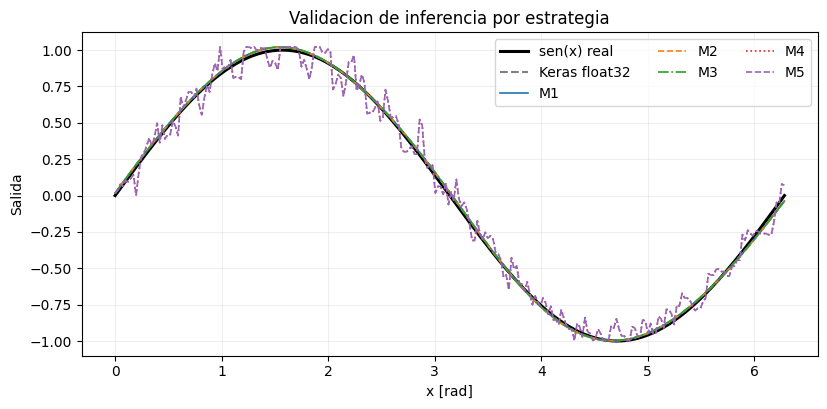

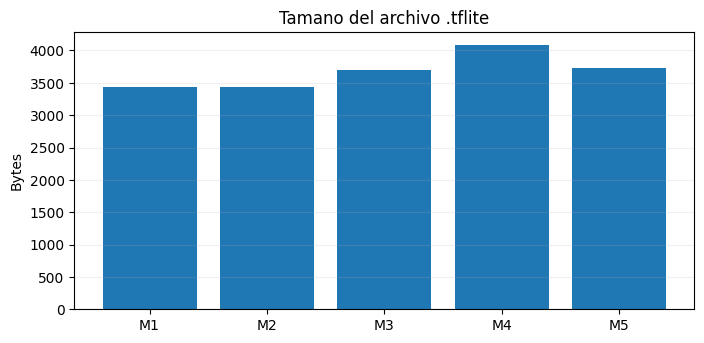

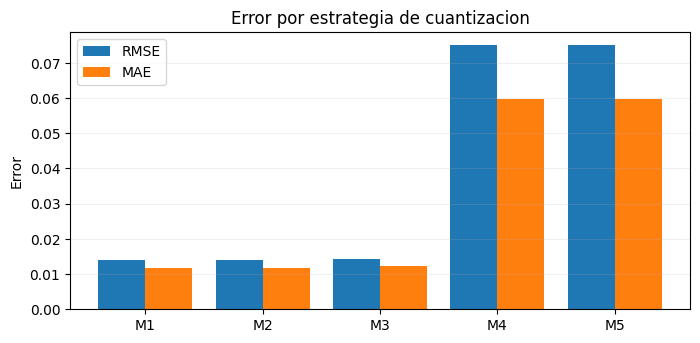

In [25]:
def predict_tflite(blob, x_values, verbose=True, name=''):
    lite = tf.lite.Interpreter(model_content=blob)
    lite.allocate_tensors()
    inp = lite.get_input_details()[0]
    out = lite.get_output_details()[0]
    in_scale, in_zero = inp['quantization']
    out_scale, out_zero = out['quantization']
    in_int = inp['dtype'] == np.int8
    out_int = out['dtype'] == np.int8
    if verbose:
        print('%s | entrada: %s %s scale=%s zero=%s | salida: %s %s scale=%s zero=%s' % (
            name, np.dtype(inp['dtype']).name, inp['shape'].tolist(), in_scale, in_zero,
            np.dtype(out['dtype']).name, out['shape'].tolist(), out_scale, out_zero))

    predictions = []
    for value in np.asarray(x_values).reshape(-1):
        if in_int:
            q = int(np.clip(np.rint(float(value) / in_scale + in_zero), -128, 127))
            lite.set_tensor(inp['index'], np.array([[q]], dtype=np.int8))
        else:
            lite.set_tensor(inp['index'], np.array([[value]], dtype=np.float32))
        lite.invoke()
        result = lite.get_tensor(out['index']).reshape(-1)[0]
        if out_int:
            predictions.append((int(result) - out_zero) * out_scale)
        else:
            predictions.append(float(result))
    return np.asarray(predictions, dtype=np.float32)


preds = {}
metrics = {}
for key, blob in tflite_models.items():
    preds[key] = predict_tflite(blob, X_test, name=key)
    metrics[key] = error_metrics(y_true, preds[key])
    print(key, json.dumps(metrics[key]))
    print('   Diferencia RMSE contra Keras float32: %.5f' % (metrics[key]['RMSE'] - metric_fp32['RMSE']))

# Tabla: tamano, reduccion, RMSE y MAE
size_m1 = len(tflite_models['M1'])
print('\nModelo  Bytes  Reduccion%   RMSE      MAE')
for key, blob in tflite_models.items():
    red = (size_m1 - len(blob)) / size_m1 * 100
    print('%-6s  %5d  %9.1f   %.5f   %.5f' % (
        key, len(blob), red, metrics[key]['RMSE'], metrics[key]['MAE']))

# Grafica de predicciones
plt.figure(figsize=(9.5, 4.2))
plt.plot(X_test[:, 0], y_true, 'k', label='sen(x) real', linewidth=2.2)
plt.plot(X_test[:, 0], pred_fp32, '--', color='gray', label='Keras float32')
styles = {'M1': '-', 'M2': '--', 'M3': '-.', 'M4': ':', 'M5': '--'}
for key in tflite_models:
    plt.plot(X_test[:, 0], preds[key], styles[key], linewidth=1.2, label=key)
plt.xlabel('x [rad]'); plt.ylabel('Salida')
plt.title('Validacion de inferencia por estrategia')
plt.legend(ncol=3); plt.grid(alpha=.2); plt.show()

# Barras de tamano y de error
keys = list(tflite_models)
x_pos = np.arange(len(keys))

plt.figure(figsize=(8, 3.6))
plt.bar(keys, [len(tflite_models[k]) for k in keys])
plt.ylabel('Bytes'); plt.title('Tamano del archivo .tflite')
plt.grid(axis='y', alpha=.2); plt.show()

plt.figure(figsize=(8, 3.6))
plt.bar(x_pos - 0.2, [metrics[k]['RMSE'] for k in keys], width=0.4, label='RMSE')
plt.bar(x_pos + 0.2, [metrics[k]['MAE'] for k in keys], width=0.4, label='MAE')
plt.xticks(x_pos, keys); plt.ylabel('Error')
plt.title('Error por estrategia de cuantizacion')
plt.legend(); plt.grid(axis='y', alpha=.2); plt.show()

## 6. Exportar automáticamente `model.h`

El modelo `.tflite` es binario; **Arduino IDE no lo puede enlazar como una variable por sí solo**. Lo convertimos a `const unsigned char g_model[]`, con alineación de 16 bytes.

**No copies manualmente miles de números:** el siguiente paso genera el archivo a partir del modelo real entrenado y cuantizado.

In [26]:
def tflite_to_header(blob, symbol='g_model', desc=''):
    body = '\n'.join(
        '  ' + ', '.join(f'0x{b:02x}' for b in blob[i:i+12]) + ','
        for i in range(0, len(blob), 12)
    )
    return (f'#pragma once\n#include <stdint.h>\n\n'
            f'// Modelo {desc} generado por Google Colab. No editar.\n'
            f'alignas(16) const unsigned char {symbol}[] = {{\n{body}\n}};\n'
            f'const unsigned int {symbol}_len = sizeof({symbol});\n')

DESCS = {
    'M1': 'FP32 sin cuantizar',
    'M2': 'rango dinamico',
    'M3': 'Float16',
    'M4': 'entero con E/S float32',
    'M5': 'INT8 completo',
}

for key, blob in tflite_models.items():
    sketch_dir = OUTPUT / f'Sketch_{key}'
    sketch_dir.mkdir(exist_ok=True)
    header_file = sketch_dir / 'model.h'
    header_file.write_text(tflite_to_header(blob, desc=DESCS[key]), encoding='utf-8')
    assert 'alignas(16)' in header_file.read_text()
    print(f'{key}: {header_file} | {len(blob)} bytes de modelo | '
          f'{header_file.stat().st_size} bytes de model.h | '
          f'primeros 12 bytes: {list(blob[:12])}')

M1: /content/tinyml_seno/Sketch_M1/model.h | 3436 bytes de modelo | 21390 bytes de model.h | primeros 12 bytes: [28, 0, 0, 0, 84, 70, 76, 51, 20, 0, 32, 0]
M2: /content/tinyml_seno/Sketch_M2/model.h | 3436 bytes de modelo | 21386 bytes de model.h | primeros 12 bytes: [28, 0, 0, 0, 84, 70, 76, 51, 20, 0, 32, 0]
M3: /content/tinyml_seno/Sketch_M3/model.h | 3700 bytes de modelo | 23007 bytes de model.h | primeros 12 bytes: [28, 0, 0, 0, 84, 70, 76, 51, 20, 0, 32, 0]
M4: /content/tinyml_seno/Sketch_M4/model.h | 4080 bytes de modelo | 25364 bytes de model.h | primeros 12 bytes: [32, 0, 0, 0, 84, 70, 76, 51, 0, 0, 0, 0]
M5: /content/tinyml_seno/Sketch_M5/model.h | 3728 bytes de modelo | 23185 bytes de model.h | primeros 12 bytes: [32, 0, 0, 0, 84, 70, 76, 51, 0, 0, 0, 0]


## 7. Generar el sketch de Arduino IDE

El sketch incluye el intérprete TFLM mediante `Chirale_TensorFlowLite`, inicializa una **arena de tensores de 24 KiB**, y convierte correctamente los datos `float` a INT8 y viceversa usando los parámetros del propio modelo.

Usamos `AllOpsResolver` para simplificar esta primera práctica. **En un curso avanzado conviene reemplazarlo por `MicroMutableOpResolver` con únicamente las operaciones requeridas** y comparar el tamaño de Flash.

El programa recorre el intervalo $[0,2\pi]$ y emite dos series (`real` y `pred`) al **Serial Plotter**, sin necesidad de sensores. La arena y los kernels pueden ajustarse después de la primera compilación.

In [27]:
SKETCH = r'''// TinyML 2026 | sen(x) con modelo @@NAME@@ | Resolver: @@RESOLVER_KIND@@
// Placas: Arduino Nano 33 BLE Sense / Rev2. Biblioteca: Chirale_TensorFlowLite.
#include <Arduino.h>
#include <math.h>
#include <stdint.h>
#include <Chirale_TensorFlowLite.h>
@@RESOLVER_INCLUDE@@
#include "tensorflow/lite/micro/micro_interpreter.h"
#include "tensorflow/lite/schema/schema_generated.h"
#include "model.h"

// 0 = Serial Plotter (real y pred), 1 = cronometrar inferencias.
#define MEDIR_TIEMPO 0
// Poner en 0 si la biblioteca no tiene arena_used_bytes().
#define USE_ARENA_USED 1

constexpr int kTensorArenaSize = @@ARENA@@;
constexpr int kNumInferencias = @@NRUNS@@;
constexpr float kDosPi = 6.28318530718f;
alignas(16) uint8_t tensor_arena[kTensorArenaSize];

const tflite::Model* net = nullptr;
tflite::MicroInterpreter* interpreter = nullptr;
TfLiteTensor* input_tensor = nullptr;
TfLiteTensor* output_tensor = nullptr;

void fatal(const char* message) {
  Serial.println(message);
  while (true) { delay(1000); }
}

void set_input(float x) {
  if (input_tensor->type == kTfLiteInt8) {
    // q = round(x / scale) + zero_point, saturada a [-128, 127]
    int q = (int)lroundf(x / input_tensor->params.scale) + input_tensor->params.zero_point;
    if (q < -128) q = -128;
    if (q >  127) q =  127;
    input_tensor->data.int8[0] = (int8_t)q;
  } else {
    input_tensor->data.f[0] = x;
  }
}

float get_output() {
  if (output_tensor->type == kTfLiteInt8) {
    return (float)(output_tensor->data.int8[0] - output_tensor->params.zero_point)
           * output_tensor->params.scale;
  }
  return output_tensor->data.f[0];
}

void setup() {
  Serial.begin(115200);
  unsigned long inicio = millis();
  while (!Serial && millis() - inicio < 3000) { delay(10); }

  net = tflite::GetModel(g_model);
  if (net->version() != TFLITE_SCHEMA_VERSION) {
    fatal("ERROR: version de schema incompatible.");
  }

@@RESOLVER_DECL@@
  static tflite::MicroInterpreter static_interpreter(
      net, resolver, tensor_arena, kTensorArenaSize);
  interpreter = &static_interpreter;

  if (interpreter->AllocateTensors() != kTfLiteOk) {
    fatal("ERROR: AllocateTensors. Revisar arena, operadores o versiones.");
  }
  input_tensor = interpreter->input(0);
  output_tensor = interpreter->output(0);

  Serial.print("modelo: "); Serial.println("@@NAME@@");
  Serial.print("tipo entrada (1=float32, 9=int8): "); Serial.println((int)input_tensor->type);
  Serial.print("tipo salida: "); Serial.println((int)output_tensor->type);
  Serial.print("scale/zero entrada: "); Serial.print(input_tensor->params.scale, 8);
  Serial.print(" / "); Serial.println(input_tensor->params.zero_point);
  Serial.print("scale/zero salida: "); Serial.print(output_tensor->params.scale, 8);
  Serial.print(" / "); Serial.println(output_tensor->params.zero_point);
  Serial.print("kTensorArenaSize: "); Serial.println(kTensorArenaSize);
#if USE_ARENA_USED
  Serial.print("arena_used_bytes: "); Serial.println((unsigned long)interpreter->arena_used_bytes());
#endif

  // Inferencia de calentamiento
  set_input(0.0f);
  if (interpreter->Invoke() != kTfLiteOk) { fatal("ERROR: fallo de inferencia."); }
}

void loop() {
#if MEDIR_TIEMPO
  static uint32_t tiempos[kNumInferencias];
  for (int i = 0; i < kNumInferencias; i++) {
    set_input(kDosPi * (float)i / (float)(kNumInferencias - 1));
    uint32_t t_ini = micros();
    TfLiteStatus st = interpreter->Invoke();
    uint32_t t_fin = micros();
    if (st != kTfLiteOk) { fatal("ERROR: fallo de inferencia."); }
    tiempos[i] = t_fin - t_ini;
  }
  uint32_t minimo = tiempos[0], maximo = tiempos[0];
  uint64_t suma = 0;
  for (int i = 0; i < kNumInferencias; i++) {
    if (tiempos[i] < minimo) minimo = tiempos[i];
    if (tiempos[i] > maximo) maximo = tiempos[i];
    suma += tiempos[i];
  }
  float media = (float)suma / (float)kNumInferencias;
  float var = 0.0f;
  for (int i = 0; i < kNumInferencias; i++) {
    float d = (float)tiempos[i] - media;
    var += d * d;
  }
  float desv = sqrtf(var / (float)kNumInferencias);
  Serial.print("[tiempo] n="); Serial.print(kNumInferencias);
  Serial.print(" min_us="); Serial.print(minimo);
  Serial.print(" max_us="); Serial.print(maximo);
  Serial.print(" prom_us="); Serial.print(media, 3);
  Serial.print(" desv_us="); Serial.println(desv, 3);
  delay(3000);
#else
  static uint16_t paso = 0;
  constexpr uint16_t kPasos = 128;
  float x = kDosPi * (float)(paso % kPasos) / (float)(kPasos - 1);
  paso++;
  set_input(x);
  if (interpreter->Invoke() != kTfLiteOk) { fatal("ERROR: fallo de inferencia."); }
  Serial.print("real:"); Serial.print(sinf(x), 4);
  Serial.print(",pred:"); Serial.println(get_output(), 4);
  delay(80);
#endif
}'''

OP_ADD = {
    'FULLY_CONNECTED': 'AddFullyConnected',
    'TANH': 'AddTanh',
    'QUANTIZE': 'AddQuantize',
    'DEQUANTIZE': 'AddDequantize',
}
TENSOR_ARENA_BYTES = 24 * 1024
N_TIMING_RUNS = 100


def get_op_names(blob):
    it = tf.lite.Interpreter(model_content=blob)
    it.allocate_tensors()
    try:
        return [op['op_name'] for op in it._get_ops_details() if op['op_name'] != 'DELEGATE']
    except Exception:
        return ['FULLY_CONNECTED', 'TANH']


def build_sketch(key, blob, min_resolver):
    kind = 'MicroMutableOpResolver' if min_resolver else 'AllOpsResolver'
    folder_name = f'Sketch_{key}_{"minops" if min_resolver else "allops"}'
    folder = OUTPUT / folder_name
    folder.mkdir(exist_ok=True)

    if min_resolver:
        ops = sorted(set(get_op_names(blob)))
        lines = [f'  static tflite::MicroMutableOpResolver<{len(ops)}> resolver;']
        for op in ops:
            lines.append(f'  resolver.{OP_ADD[op]}();' if op in OP_ADD
                         else f'  // TODO: operador sin mapeo: {op}')
        decl = '\n'.join(lines)
        include = '#include "tensorflow/lite/micro/micro_mutable_op_resolver.h"'
    else:
        decl = '  static tflite::AllOpsResolver resolver;'
        include = '#include "tensorflow/lite/micro/all_ops_resolver.h"'

    code = (SKETCH.replace('@@NAME@@', key)
                  .replace('@@RESOLVER_KIND@@', kind)
                  .replace('@@RESOLVER_INCLUDE@@', include)
                  .replace('@@RESOLVER_DECL@@', decl)
                  .replace('@@ARENA@@', str(TENSOR_ARENA_BYTES))
                  .replace('@@NRUNS@@', str(N_TIMING_RUNS)))
    (folder / f'{folder_name}.ino').write_text(code, encoding='utf-8')
    (folder / 'model.h').write_text(tflite_to_header(blob), encoding='utf-8')
    return folder


for key, blob in tflite_models.items():
    for min_res in (False, True):
        folder = build_sketch(key, blob, min_res)
        print('Sketch:', folder.name, '| modelo:', len(blob), 'bytes')

Sketch: Sketch_M1_allops | modelo: 3436 bytes
Sketch: Sketch_M1_minops | modelo: 3436 bytes
Sketch: Sketch_M2_allops | modelo: 3436 bytes
Sketch: Sketch_M2_minops | modelo: 3436 bytes
Sketch: Sketch_M3_allops | modelo: 3700 bytes
Sketch: Sketch_M3_minops | modelo: 3700 bytes
Sketch: Sketch_M4_allops | modelo: 4080 bytes
Sketch: Sketch_M4_minops | modelo: 4080 bytes
Sketch: Sketch_M5_allops | modelo: 3728 bytes
Sketch: Sketch_M5_minops | modelo: 3728 bytes


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 8. Instalación de Arduino IDE y biblioteca (pasos detallados)

**A. Instalar Arduino IDE 2.x**

1. Descarga **Arduino IDE 2.x** desde [arduino.cc/en/software](https://www.arduino.cc/en/software) e instálalo en tu computadora (no dentro de Colab).
2. Abre **Herramientas → Placa → Gestor de placas** y busca **Arduino Mbed OS Nano Boards**. Instala ese paquete de soporte.
3. Conecta la tarjeta por USB; en **Herramientas → Placa** selecciona **Arduino Nano 33 BLE** (la opción del núcleo Mbed para Nano 33 BLE / Sense / Sense Rev2 según el paquete instalado). Elige el puerto serie que aparece al conectar la placa.
4. Abre **Herramientas → Administrar bibliotecas** y busca **Chirale**. Instala **Chirale_TensorFlowLite** (versión 2.0.0 si está disponible). En algunos listados el nombre aparece capitalizado como `Chirale_TensorFLowLite`; el header que utiliza el programa es `Chirale_TensorFlowLite.h`.
5. Si la biblioteca no aparece en el Gestor: descarga el ZIP desde [spaziochirale/Chirale_TensorFlowLite](https://github.com/spaziochirale/Chirale_TensorFlowLite) (botón **Code → Download ZIP**) y usa **Programa → Incluir librería → Añadir biblioteca .ZIP…**. Reinicia el IDE si fuera necesario. **No instales simultáneamente varias bibliotecas que exporten las mismas cabeceras de TFLM** (`Arduino_TensorFlowLite` archivada, Chirale, etc.) para evitar colisiones de dependencias.

**B. Abrir el proyecto generado**

6. Ejecuta todas las celdas hasta el final, descarga **`TinyML_Seno_Arduino_Nano33BLE.zip`** y **descomprímelo** (no abras el ZIP directamente como sketch).
7. En Arduino IDE: **Archivo → Abrir → `TinyML_Seno_Nano33BLE/TinyML_Seno_Nano33BLE.ino`**. Comprueba que **`model.h`** esté en la misma carpeta que el archivo `.ino` (lo genera automáticamente este notebook).
8. Haz clic en **Verificar** para compilar y después **Subir**.
9. Abre **Herramientas → Serial Plotter**, configura **115200 baudios** y comprueba las dos curvas `real` y `pred`.

**C. Si trabajas en Ubuntu/Linux**

- Verifica el puerto con `ls /dev/ttyACM* /dev/ttyUSB* 2>/dev/null`.
- Si no tienes permisos para abrir el puerto, suele ayudar: `sudo usermod -aG dialout "$USER"`; luego **cierra sesión y vuelve a iniciarla**. No uses `chmod 777` como solución permanente.
- Si la placa no carga, prueba pulsar dos veces el botón reset para entrar al bootloader y vuelve a elegir el puerto.

**D. Resolución de errores frecuentes**

| Síntoma | Causa posible | Comprobación / solución |
|---|---|---|
| `Chirale_TensorFlowLite.h: No such file` | Biblioteca ausente o instalada en carpeta incorrecta | Reinstalar biblioteca y reiniciar IDE |
| `tensorflow/lite/micro/...: No such file` | Biblioteca equivocada o incompleta | Quitar duplicados y verificar distribución Chirale |
| `schema incompatible` | Modelo y runtime usan esquema TFLite distinto | Revisar versiones del conversor de Colab y del runtime de Arduino |
| `AllocateTensors failed` | Arena insuficiente **o** operador/versiones incompatibles | Aumentar `kTensorArenaSize` y revisar logs/operadores |
| El sketch compila pero no aparece una curva | Puerto/baudios incorrectos, mensaje de error o cable USB de solo carga | Abrir el monitor serie a 115200 y comprobar mensajes |
| Resultados muy alejados de `sin(x)` | Error de cuantización o uso de otro `model.h` | Revisar los metadatos de INT8 y copiar el header generado |

> **Advertencia metodológica:** la biblioteca Chirale proviene de 2024 y no garantiza compatibilidad con todas las versiones futuras del conversor TensorFlow. El notebook valida la inferencia TFLite en Python; **la compilación y la ejecución en la placa son verificaciones que debe realizar cada estudiante**. Si un modelo generado por TensorFlow actual usa versiones de operadores más recientes que la biblioteca Arduino, hay que ajustar la versión de herramientas o reconstruir TFLM, no copiar arbitrariamente bytes a otro formato.

#### Parte 2

In [28]:
rows_a1 = []
total = 0
for layer in model.layers:
    w, b = layer.get_weights()
    n = int(w.size + b.size)
    total += n
    rows_a1.append((layer.name, '%dx%d + %d' % (w.shape[0], w.shape[1], b.size), n, n * 4))

print('%-10s %-12s %10s %12s' % ('Capa', 'W + b', 'Parametros', 'Bytes FP32'))
for r in rows_a1:
    print('%-10s %-12s %10d %12d' % r)
print('%-10s %-12s %10d %12d' % ('TOTAL', '', total, total * 4))

print()
for key, blob in tflite_models.items():
    print('%s: .tflite = %d bytes | pesos FP32 teoricos = %d bytes | diferencia = %d bytes'
          % (key, len(blob), total * 4, len(blob) - total * 4))

Capa       W + b        Parametros   Bytes FP32
dense_9    1x16 + 16            32          128
dense_10   16x16 + 16          272         1088
dense_11   16x1 + 1             17           68
TOTAL                          321         1284

M1: .tflite = 3436 bytes | pesos FP32 teoricos = 1284 bytes | diferencia = 2152 bytes
M2: .tflite = 3436 bytes | pesos FP32 teoricos = 1284 bytes | diferencia = 2152 bytes
M3: .tflite = 3700 bytes | pesos FP32 teoricos = 1284 bytes | diferencia = 2416 bytes
M4: .tflite = 4080 bytes | pesos FP32 teoricos = 1284 bytes | diferencia = 2796 bytes
M5: .tflite = 3728 bytes | pesos FP32 teoricos = 1284 bytes | diferencia = 2444 bytes


#### Parte 6

In [31]:
TRAIN_B = (-np.pi, np.pi)
WIDE = (-2 * np.pi, 2 * np.pi)
N_WIDE = 512

rngB = np.random.default_rng(SEED + 1)
X_train_B = rngB.uniform(*TRAIN_B, size=(1600, 1)).astype(np.float32)
y_train_B = (np.sin(X_train_B) + rngB.normal(0, 0.015, size=X_train_B.shape)).astype(np.float32)
X_val_B = rngB.uniform(*TRAIN_B, size=(320, 1)).astype(np.float32)
y_val_B = np.sin(X_val_B).astype(np.float32)

tf.keras.utils.set_random_seed(SEED)
model_B = tf.keras.Sequential([
    tf.keras.Input(shape=(1,), dtype=tf.float32),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(1),
], name='seno_B')
model_B.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.005), loss='mse', metrics=['mae'])
history_B = model_B.fit(
    X_train_B, y_train_B, validation_data=(X_val_B, y_val_B),
    epochs=200, batch_size=64, verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)],
)
print('Epocas modelo B:', len(history_B.history['loss']))

blob_B = convert_int8(model_B, make_rep_fn(*TRAIN_B))
(OUTPUT / 'modelo_seno_B_int8.tflite').write_bytes(blob_B)

X_wide = np.linspace(*WIDE, N_WIDE, dtype=np.float32).reshape(-1, 1)
y_wide = np.sin(X_wide).reshape(-1)

cases = {
    'A [0, 2pi]': (model, tflite_models['M5'], (0.0, 2 * np.pi)),
    'B [-pi, pi]': (model_B, blob_B, TRAIN_B),
}
res = {}
for name, (kmodel, blob, (lo, hi)) in cases.items():
    p_fp = kmodel.predict(X_wide, verbose=0).reshape(-1)
    p_q = predict_tflite(blob, X_wide, verbose=False)
    rows, _ = collect_tensors(blob)
    r_in = [r for r in rows if r['rol'] == 'entrada'][0]
    inside = (X_wide[:, 0] >= lo) & (X_wide[:, 0] <= hi)
    res[name] = {
        'fp': p_fp, 'q': p_q, 'interval': (lo, hi),
        'sat': n_saturated(X_wide, r_in['scale'], r_in['zp']),
        'fp_in': error_metrics(y_wide[inside], p_fp[inside])['RMSE'],
        'fp_out': error_metrics(y_wide[~inside], p_fp[~inside])['RMSE'],
        'q_in': error_metrics(y_wide[inside], p_q[inside])['RMSE'],
        'q_out': error_metrics(y_wide[~inside], p_q[~inside])['RMSE'],
    }

print('%-12s %10s %10s %11s %11s %8s' % ('Modelo', 'fp dentro', 'fp fuera', 'int8 dentro', 'int8 fuera', 'Satur.'))
for name, r in res.items():
    print('%-12s %10.4f %10.4f %11.4f %11.4f %8d' % (
        name, r['fp_in'], r['fp_out'], r['q_in'], r['q_out'], r['sat']))

fig, axes = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True)
for ax, (name, r) in zip(axes, res.items()):
    ax.plot(X_wide[:, 0], y_wide, 'k', linewidth=2.2, label='sen(x) real')
    ax.plot(X_wide[:, 0], r['fp'], '--', label='float32')
    ax.plot(X_wide[:, 0], r['q'], ':', linewidth=2, label='INT8')
    ax.axvspan(*r['interval'], color='green', alpha=0.08, label='intervalo de entrenamiento')
    ax.set_title('Modelo ' + name); ax.set_ylabel('Salida')
    ax.legend(ncol=4, fontsize=8); ax.grid(alpha=.2)
axes[1].set_xlabel('x [rad]')
plt.tight_layout(); plt.show()

Epocas modelo B: 200


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


KeyError: 'scale'

#### Parte 8

In [30]:
import io, contextlib

N_REP = 256   # mismo numero de muestras en los cuatro modelos
CALIB = {
    'C1': (0.0, 2 * np.pi),
    'C2': (0.0, np.pi),
    'C3': (np.pi, 2 * np.pi),
    'C4': (0.0, np.pi / 2),
}

def make_rep_fn(lo, hi, n=N_REP):
    xs = np.linspace(lo, hi, n, dtype=np.float32)
    def gen():
        for v in xs:
            yield [np.array([[v]], dtype=np.float32)]
    return gen

def convert_int8(keras_model, rep_fn):
    conv = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    conv.representative_dataset = rep_fn
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8
    conv.inference_output_type = tf.int8
    with contextlib.redirect_stdout(io.StringIO()):   # silencia el log de conversion
        return conv.convert()

def expected_in_params(lo, hi):
    # Teoria: rango asimetrico int8; se extiende el rango para incluir el 0.0
    lo2, hi2 = min(lo, 0.0), max(hi, 0.0)
    scale = (hi2 - lo2) / 255.0
    zp = int(np.round(-128 - lo2 / scale))
    return scale, zp

def n_saturated(x, scale, zp):
    q = np.rint(np.asarray(x).reshape(-1) / scale) + zp
    return int(np.sum((q < -128) | (q > 127)))

c_blobs, c_rows, c_preds, c_metrics, c_sat = {}, {}, {}, {}, {}
for key, (lo, hi) in CALIB.items():
    blob = convert_int8(model, make_rep_fn(lo, hi))
    c_blobs[key] = blob
    (OUTPUT / f'modelo_seno_{key}_calib.tflite').write_bytes(blob)
    rows, _ = collect_tensors(blob)
    c_rows[key] = rows
    c_preds[key] = predict_tflite(blob, X_test, verbose=False)
    c_metrics[key] = error_metrics(y_true, c_preds[key])
    r_in = [r for r in rows if r['rol'] == 'entrada'][0]
    c_sat[key] = n_saturated(X_test, r_in['scale'], r_in['zp'])

# Parte B: entrada, salida y tamano
print('Parte B: parametros de entrada y salida')
print('%-4s %-16s %10s %6s %12s %8s %10s %6s %6s' % (
    'Mod', 'Calibracion', 'scale_in', 'zp_in', 'scale_in_teo', 'zp_teo', 'scale_out', 'zp_out', 'Bytes'))
for key, (lo, hi) in CALIB.items():
    r_in = [r for r in c_rows[key] if r['rol'] == 'entrada'][0]
    r_out = [r for r in c_rows[key] if r['rol'] == 'salida'][0]
    th_s, th_z = expected_in_params(lo, hi)
    print('%-4s [%5.2f, %5.2f]   %10.6f %6d %12.6f %8d %10.6f %6d %6d' % (
        key, lo, hi, r_in['scale'], r_in['zp'], th_s, th_z, r_out['scale'], r_out['zp'], len(c_blobs[key])))

print('\nScale y zero_point de las activaciones intermedias (en orden):')
for key in CALIB:
    acts = [r for r in c_rows[key] if r['rol'] == 'activacion']
    print(key, [('%.5f' % r['scale'], r['zp']) for r in acts])

# Parte C: errores sobre [0, 2pi]
print('\nParte C: errores sobre [0, 2pi]')
print('%-14s %9s %9s %9s %14s' % ('Modelo', 'RMSE', 'MAE', 'Satur.', 'RMSE cuant.'))
print('%-14s %9.5f %9.5f %9s %14s' % ('Keras float32', metric_fp32['RMSE'], metric_fp32['MAE'], '-', '-'))
for key in CALIB:
    rmse_q = float(np.sqrt(np.mean((pred_fp32 - c_preds[key]) ** 2)))
    print('%-14s %9.5f %9.5f %9d %14.5f' % (
        key, c_metrics[key]['RMSE'], c_metrics[key]['MAE'], c_sat[key], rmse_q))
# RMSE = contra sen(x) real. RMSE cuant. = INT8 contra float32 (error solo de cuantizar).

fig, axes = plt.subplots(2, 1, figsize=(9.5, 7), sharex=True)
axes[0].plot(X_test[:, 0], y_true, 'k', linewidth=2.2, label='sen(x) real')
axes[0].plot(X_test[:, 0], pred_fp32, '--', color='gray', label='Keras float32')
for key in CALIB:
    axes[0].plot(X_test[:, 0], c_preds[key], label=key)
axes[0].set_ylabel('Salida'); axes[0].set_title('Calibracion C1..C4')
axes[0].legend(ncol=3); axes[0].grid(alpha=.2)
for key in CALIB:
    axes[1].plot(X_test[:, 0], np.abs(y_true - c_preds[key]), label=key)
axes[1].plot(X_test[:, 0], np.abs(y_true - pred_fp32), '--', color='gray', label='Keras float32')
axes[1].set_xlabel('x [rad]'); axes[1].set_ylabel('|error|')
axes[1].legend(ncol=3); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.show()

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


KeyError: 'scale'